# Prédiction de la qualité de soudures d'acier — base *welddb* (Cambridge)

**Équipe n° __** · *Nom Prénom 1* (email) · *Nom Prénom 2* (email) · *Nom Prénom 3* (email)
**Date :** 13 octobre 2026

> Ce notebook tient lieu de rapport : chaque section de code est précédée d'un texte qui explique **ce qui est fait**, **pourquoi**, et suivie d'une **analyse des résultats**.
> ⚠️ Les commentaires chiffrés renvoient à l'exécution de référence. Après un *Restart & Run All*, vérifier que les valeurs citées correspondent aux sorties affichées.

### Plan
1. Problématique et traduction en tâche de Machine Learning
2. Chargement et description de la base
3. Pré-traitement (choix justifiés)
4. Variables cibles et définition de la qualité
5. Analyse exploratoire : ACP
6. Protocole d'évaluation (anti-fuite)
7. Méthodes : modèles supervisés et apprentissage semi-supervisé
8. Résultats comparatifs (validation croisée groupée)
9. Optimisation, calibrage du seuil de sécurité et évaluation sur test réservé
10. Interprétation et recommandations pour une bonne soudure
11. Décision combinée Traction + Ductilité
12. Conclusion, limites et perspectives
13. Organisation (GANTT) et références

## 1. Problématique et traduction en tâche de ML

**Contexte.** La qualité d'une soudure d'acier conditionne la tenue mécanique de structures critiques (pipes d'éoliennes, appareils sous pression). Aujourd'hui, ce savoir est surtout transmis d'expert à expert. L'objectif est d'extraire de la base de données des règles **prédictives** et **interprétables**.

**Traduction ML.** Une soudure n'a pas une « note de qualité » unique dans la base : on dispose de mesures mécaniques (limite d'élasticité, résistance à la traction, allongement, résilience Charpy). Nous avons donc choisi de :

1. **définir la qualité comme une conformité à des critères normatifs** (soudure acceptable / non acceptable), ce qui transforme le problème en **classification binaire** ;
2. séparer la qualité en **deux tâches complémentaires**, car elles ne sont pas mesurées sur les mêmes soudures :
   - **Traction** (résistance mécanique) ;
   - **Ductilité / ténacité** (essai Charpy, résistance à la rupture fragile) ;
3. exploiter les soudures **non labellisées** (une propriété non mesurée) via un **apprentissage semi-supervisé**.

**Pourquoi la classification plutôt que la régression ?** La décision industrielle est binaire (accepter / rejeter), et les critères normatifs sont des seuils. Une régression sur chaque propriété suivie d'un seuillage serait une alternative valable (voir § 12, perspectives).

**Coût asymétrique des erreurs.** Accepter une mauvaise soudure (faux positif) est bien plus grave que rejeter une bonne soudure. Toute l'évaluation est donc orientée vers la **détection de la classe 0 (non conforme)**.

## 2. Chargement et description de la base

La base *welddb* (Cooper, Bhadeshia, MacKay) contient 1652 soudures décrites par 44 colonnes :
- **21 variables de composition chimique** (wt% ou ppm) ;
- **9 variables de procédé** : courant, tension, type de courant, polarité, apport de chaleur (kJ/mm), température entre passes, type de procédé, traitement thermique post-soudage (PWHT : température, durée) ;
- **propriétés mécaniques et microstructurales** (cibles potentielles).

Les valeurs manquantes sont codées `N`. Certaines valeurs sont des **inégalités** (`<0.01`) ou des formats composites (`67tot33res` pour l'azote : total / résiduel).

In [2]:
import os
import re
import tarfile
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RANDOM_STATE = 42

TAR_URL = "https://www.phase-trans.msm.cam.ac.uk/map/data/tar/welddb.tar"
DATA_DIR = os.path.join("..", "data")
TAR_PATH = os.path.join(DATA_DIR, "welddb.tar")
DATA_PATH = os.path.join(DATA_DIR, "welddb.data")

# Download and extract only if needed
os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(DATA_PATH):
    req = urllib.request.Request(TAR_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as response, open(TAR_PATH, "wb") as f:
        f.write(response.read())
    with tarfile.open(TAR_PATH) as tar:
        tar.extract("welddb.data", path=DATA_DIR)

# 'N' encodes a missing value in the raw file
df_raw = pd.read_csv(DATA_PATH, sep=r"\s+", na_values=["N"], header=None)
print(f"Raw dataset shape: {df_raw.shape}")

Raw dataset shape: (1652, 44)


In [3]:
COLUMN_NAMES = [
    # Chemical composition (21)
    "C_wt", "Si_wt", "Mn_wt", "S_wt", "P_wt", "Ni_wt", "Cr_wt", "Mo_wt",
    "V_wt", "Cu_wt", "Co_wt", "W_wt", "O_ppm", "Ti_ppm", "N_ppm", "Al_ppm",
    "B_ppm", "Nb_ppm", "Sn_ppm", "As_ppm", "Sb_ppm",
    # Welding process (7)
    "Current_A", "Voltage_V", "AC_DC", "Polarity", "Heat_input", "Interpass_temp", "Weld_type",
    # Post-weld heat treatment (2)
    "PWHT_temp", "PWHT_time",
    # Mechanical / microstructural properties
    "Yield_strength", "UTS", "Elongation", "Reduction_area", "Charpy_temp", "Charpy_energy",
    "Hardness", "FATT_50", "Primary_ferrite", "Ferrite_2nd_phase", "Acicular_ferrite",
    "Martensite", "Ferrite_carbide", "Weld_ID",
]
COMPOSITION_COLS = COLUMN_NAMES[:21]

df = df_raw.copy()
df.columns = COLUMN_NAMES
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1652 entries, 0 to 1651
Data columns (total 44 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   C_wt               1652 non-null   float64
 1   Si_wt              1652 non-null   float64
 2   Mn_wt              1652 non-null   float64
 3   S_wt               1648 non-null   str    
 4   P_wt               1642 non-null   float64
 5   Ni_wt              697 non-null    float64
 6   Cr_wt              784 non-null    float64
 7   Mo_wt              793 non-null    str    
 8   V_wt               928 non-null    str    
 9   Cu_wt              578 non-null    str    
 10  Co_wt              129 non-null    str    
 11  W_wt               75 non-null     str    
 12  O_ppm              1256 non-null   float64
 13  Ti_ppm             935 non-null    str    
 14  N_ppm              1242 non-null   str    
 15  Al_ppm             905 non-null    str    
 16  B_ppm              504 non-null    

### 2.1 Taux de valeurs manquantes

Le graphique suivant guide les choix de pré-traitement : une colonne très creuse ne peut pas être imputée de façon fiable.

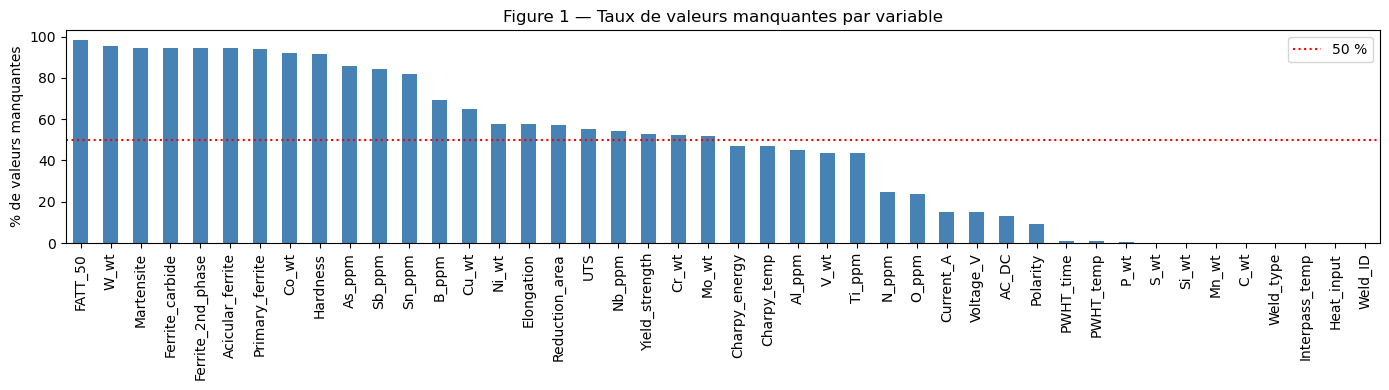

In [4]:
missing = df.isna().mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(14, 4))
missing.plot.bar(ax=ax, color="steelblue")
ax.axhline(50, color="red", linestyle=":", label="50 %")
ax.set_ylabel("% de valeurs manquantes")
ax.set_title("Figure 1 — Taux de valeurs manquantes par variable")
ax.legend()
plt.tight_layout()
plt.show()

**Analyse**
- La **composition de base** (C, Si, Mn, S, P) est quasi complète : ce sont les éléments systématiquement dosés.
- Les **éléments d'alliage** (Ni, Cr, Mo, V, Cu, Co, W, B, Nb…) sont très souvent absents. Ce n'est pas un défaut de mesure aléatoire : en général, un élément non reporté **n'a pas été ajouté volontairement**.
- Les **cibles** sont partiellement renseignées : moins de la moitié des soudures ont un essai de traction, environ la moitié un essai Charpy. C'est ce qui motive l'approche **semi-supervisée**.
- `Hardness`, `FATT_50` et les fractions microstructurales sont trop rares pour servir de cibles.

### 2.2 Procédés de soudage

Les procédés ont des physiques différentes (différents types de soudure). Mélanger des procédés très minoritaires risque d'introduire du bruit plutôt que de l'information.

In [5]:
# Harmonise synonyms: ShMA = Shielded Metal Arc = MMA; SA = Submerged Arc
df["Weld_type"] = df["Weld_type"].replace({"ShMA": "MMA", "SA": "SMA"})

label_avail = (
    df.assign(
        has_tensile=df[["Yield_strength", "UTS", "Elongation"]].notna().all(axis=1),
        has_charpy=df["Charpy_energy"].notna(),
    )
    .groupby("Weld_type")[["has_tensile", "has_charpy"]]
    .agg(["sum", "size"])
)
display(label_avail)

has_tensile       has_charpy      
                  sum  size        sum  size
Weld_type                                   
FCA                 7    87         63    87
GMAA                4     4          0     4
GTAA                4     4          0     4
MMA               489  1180        673  1180
NGGMA               2     7          5     7
NGSAW               4    18         14    18
SAA                 4     4          0     4
SMA               127   261         61   261
TSA                24    87         63    87

**Choix.** On conserve les 4 procédés principaux (MMA, SMA, FCA, TSA) et on supprime les procédés rares (GMAA, GTAA, SAA, NGGMA, NGSAW), trop peu représentés pour être modélisés.

**L'étude porte sur MMA** (soudage manuel à l'électrode enrobée), qui représente environ 70 % de la base et l'essentiel des soudures labellisées. Entraîner un modèle unique sur tous les procédés imposerait au modèle d'apprendre aussi les différences de physique entre procédés, avec trop peu d'exemples pour SMA, FCA et TSA.

## 3. Pré-traitement des données

- **Valeurs sous le seuil de détection (`<x`)** : Remplacées par `x / 2`. La valeur réelle est comprise entre 0 et x, ce qui correspond à la pratique usuelle en chimie analytique.
- **Azote format composite (`67tot33res`)** : Conservation du premier nombre uniquement (azote total) pour homogénéiser la mesure sur l'ensemble du dataset.
- **Éléments d'alliage manquants (Ni, Cr, Mo, V, Cu, Co, W, B, Nb, Sn, As, Sb)** : Imputés à `0`. Un élément non renseigné signifie qu'il n'a pas été ajouté. Une imputation par la médiane dénaturerait la chimie de l'alliage.
- **Éléments résiduels manquants (O, N, Ti, Al)** : Imputation par la **médiane + indicateur d'absence**. Ces éléments étant toujours présents à l'état de traces, un 0 serait physiquement faux. Le flag permet au modèle de capter si l'absence de mesure porte une information.
- **Plages de température (`Interpass_temp = "150-200"`)** : Converties au milieu d'intervalle (`175`) pour conserver une variable numérique continue.
- **`Hardness` et `FATT_50`** : Supprimées du dataset car plus de 90 % des données sont manquantes.
- **Échelles de grandeur (wt%, ppm, °C, h, kJ/mm)** : Standardisées dans le pipeline. Étape requise pour la régression logistique, le SVM et l'ACP (sans impact sur les modèles d'arbres).
- **Variables catégorielles (AC/DC, polarité)** : Encodage One-Hot pour ne pas créer d'ordre artificiel entre les modalités.

Toutes les imputations et standardisations sont inclus dans un pipeline pour éviter la **fuite de données**

In [6]:
def parse_measure(val):
    # Convert raw composition strings to floats
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    if s.startswith("<"):
        return float(s[1:]) / 2  # half the detection limit
    m = re.match(r"^-?\d*\.?\d+", s)  # leading number, e.g. '67tot33res' -> 67
    return float(m.group(0)) if m else np.nan


df = df.drop(columns=["Hardness", "FATT_50"])
df = df[~df["Weld_type"].isin(["GMAA", "GTAA", "SAA", "NGGMA", "NGSAW"])].copy()

df[COMPOSITION_COLS] = df[COMPOSITION_COLS].apply(lambda col: col.map(parse_measure))

ALLOY_ELEMENTS = ["Ni_wt", "Cr_wt", "Mo_wt", "V_wt", "Cu_wt", "Co_wt", "W_wt",
                  "B_ppm", "Nb_ppm", "Sn_ppm", "As_ppm", "Sb_ppm"]
df[ALLOY_ELEMENTS] = df[ALLOY_ELEMENTS].fillna(0)

df["Interpass_temp"] = pd.to_numeric(df["Interpass_temp"].replace("150-200", "175"), errors="coerce")
for col in ["Current_A", "Voltage_V", "Heat_input", "PWHT_temp", "PWHT_time",
            "Yield_strength", "UTS", "Elongation", "Charpy_temp", "Charpy_energy"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Charpy: energies 28/50/100 J are reference levels (temperature at which this energy is reached)
is_fixed_energy = df["Charpy_energy"].isin([28, 50, 100])
df["Charpy_energy_fixed"] = np.select(
    [is_fixed_energy, df["Charpy_energy"].notna() & ~is_fixed_energy], [1, 0], default=np.nan
)

print(df["Weld_type"].value_counts())
print("\nComposition dtypes all numeric:", all(pd.api.types.is_numeric_dtype(df[c]) for c in COMPOSITION_COLS))

Weld_type
MMA    1180
SMA     261
FCA      87
TSA      87
Name: count, dtype: int64

Composition dtypes all numeric: True


In [7]:
df_mma = df[df["Weld_type"] == "MMA"].copy()
print(f"MMA : {len(df_mma)}")

MMA : 1180


## 4. Variables cibles : définition de la qualité

### 4.1 Distribution des propriétés mécaniques

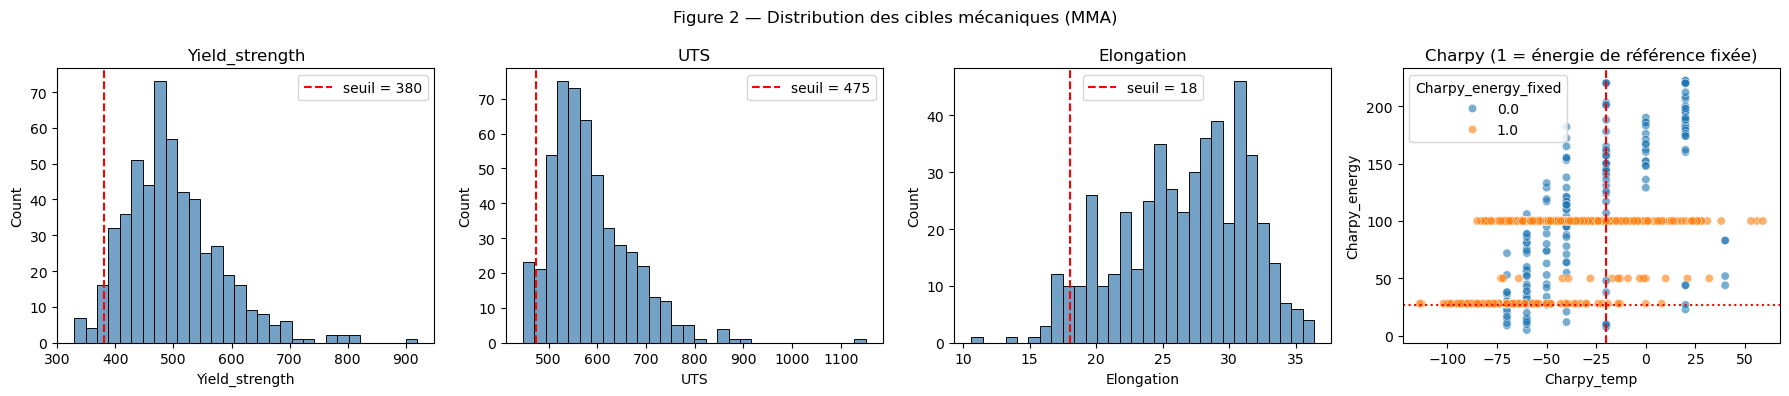

,Yield_strength,UTS,Elongation
count,526.000000,510.000000,489.000000
mean,498.477947,583.444118,26.625153
std,83.031611,84.313552,4.742954
min,329.000000,447.000000,10.600000
5%,387.500000,476.900000,18.000000
50%,486.400000,568.000000,27.400000
95%,647.500000,737.000000,33.300000
max,920.000000,1151.000000,36.400000


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (col, thr) in zip(axes[:3], [("Yield_strength", 380), ("UTS", 475), ("Elongation", 18)]):
    sns.histplot(df_mma[col].dropna(), bins=30, ax=ax, color="steelblue")
    ax.axvline(thr, color="red", linestyle="--", label=f"seuil = {thr}")
    ax.set_title(col)
    ax.legend()

charpy = df_mma.dropna(subset=["Charpy_temp", "Charpy_energy"])
sns.scatterplot(data=charpy, x="Charpy_temp", y="Charpy_energy", hue="Charpy_energy_fixed",
                palette={0: "tab:blue", 1: "tab:orange"}, alpha=0.6, ax=axes[3])
axes[3].axvline(-20, color="red", linestyle="--")
axes[3].axhline(27, color="red", linestyle=":")
axes[3].set_title("Charpy (1 = énergie de référence fixée)")
fig.suptitle("Figure 2 — Distribution des cibles mécaniques (MMA)")
plt.tight_layout()
plt.show()

display(df_mma[["Yield_strength", "UTS", "Elongation"]].describe(percentiles=[0.05, 0.5, 0.95]))

### 4.2 Critères de conformité retenus

#### Modèle Traction
Une soudure est classée conforme si elle respecte l'ensemble de ces conditions :
- $R_e \ge 380$ MPa (limite d'élasticité)
- $R_m \ge 475$ MPa (résistance à la rupture)
- $A \ge 18\,\%$ (allongement)
- $R_e / R_m \le 0{,}90$ (ratio d'écrouissage)

**Justification :**
- Les valeurs ciblent la classe **38** de la norme **EN ISO 2560-A** ($R_e \ge 380$ MPa, $470 \le R_m \le 600$ MPa, $A \ge 20\,\%$). Le seuil retenu sur l'allongement (18 %) est volontairement un peu plus tolérant que la norme.
- La limite sur le ratio $R_e / R_m \le 0{,}90$ préserve une capacité de déformation plastique suffisante avant rupture.

#### Modèle Ductilité (Charpy)
Référence visée : **27 J à −20 °C** (équivalent à l'indice « 2 » de l'EN ISO 2560-A).

Traitement différencié selon le type d'essai présent dans la base :

- **Essais à température fixée ($E$ mesuré à $T$)**
  - **Conforme (1)** : $E > 27$ J à $T \le -20$ °C
  - **Non conforme (0)** : $E \le 27$ J à $T \ge -20$ °C
  - **Non informatif (-1)** : $E > 27$ J à $T > -20$ °C, ou $E \le 27$ J à $T < -20$ °C

- **Essais à énergie fixée ($T_E$ mesurée pour $E$)**
  - **Conforme (1)** : $T_E < -20$ °C (pour des paliers de 28 J, 50 J ou 100 J)
  - **Non conforme (0)** : $T_{28} > -20$ °C (valable uniquement pour le palier 28 J)
  - **Non informatif (-1)** : $T_E \ge -20$ °C sur les paliers 50 J et 100 J

In [9]:
# --- Tensile label ---
has_tensile = df_mma[["Yield_strength", "UTS", "Elongation"]].notna().all(axis=1)
ok_tensile = (
    (df_mma["Yield_strength"] >= 380)
    & (df_mma["UTS"] >= 475)
    & (df_mma["Elongation"] >= 18)
    & (df_mma["Yield_strength"] / df_mma["UTS"] <= 0.90)
)
df_mma["Valid_Traction"] = np.where(has_tensile, np.where(ok_tensile, 1, 0), -1)

# --- Charpy label ---
fixed_E = df_mma["Charpy_energy_fixed"] == 1
fixed_T = df_mma["Charpy_energy_fixed"] == 0
T, E = df_mma["Charpy_temp"], df_mma["Charpy_energy"]

good = (fixed_E & (T < -20)) | (fixed_T & (E > 27) & (T <= -20))
bad = (fixed_E & (E == 28) & (T > -20)) | (fixed_T & (E <= 27) & (T >= -20))
df_mma["Valid_Ductile"] = np.select([good, bad], [1, 0], default=-1)

label_table = pd.DataFrame({
    "Traction": df_mma["Valid_Traction"].value_counts(),
    "Ductilité": df_mma["Valid_Ductile"].value_counts(),
}).rename(index={-1: "non labellisé (-1)", 0: "non conforme (0)", 1: "conforme (1)"})
display(label_table)
display(pd.crosstab(df_mma["Valid_Traction"], df_mma["Valid_Ductile"],
                    rownames=["Traction"], colnames=["Ductilité"]))

,Traction,Ductilité
non labellisé (-1),691,657
conforme (1),389,512
non conforme (0),100,11


Ductilité,-1,0,1
Traction,,,
-1,265,11,415
0,72,0,28
1,320,0,69


**Analyse.**
- **Traction :** la classe 0 représente environ 20 % des soudures labellisées.
- **Ductilité :** après correction physique du label, il ne reste qu'**une dizaine de soudures non conformes** (11 dans l'exécution de référence). C'est un **déséquilibre extrême**. Les métriques de ce modèle seront donc **très instables** : chaque erreur sur la classe 0 fait varier le rappel d'environ 10 points. Il faudra le garder en tête en conclusion.
- **Le tableau croisé montre que peu de soudures ont les deux labels.** On ne peut pas entraîner un modèle unique « soudure conforme » directement. C'est ce qui justifie **deux modèles séparés**

### 4.3 Variables d'entrée


On ne garde que ce qu'un soudeur contrôle avant de souder : composition, paramètres de procédé, PWHT.

In [10]:
NON_FEATURES = [
    "Weld_type", "Weld_ID", "Valid_Traction", "Valid_Ductile",
    "Charpy_temp", "Charpy_energy", "Charpy_energy_fixed",
    "Yield_strength", "UTS", "Elongation", "Reduction_area",
    "Primary_ferrite", "Ferrite_2nd_phase", "Acicular_ferrite",
    "Martensite", "Ferrite_carbide",
]
X_all = df_mma.drop(columns=NON_FEATURES)

CAT_COLS = X_all.select_dtypes(exclude="number").columns.tolist()
NUM_COLS = X_all.select_dtypes(include="number").columns.tolist()
print(f"{len(NUM_COLS)} numeric features, categorical features: {CAT_COLS}")
assert set(CAT_COLS) <= {"AC_DC", "Polarity"}, f"Unexpected non-numeric columns: {CAT_COLS}"

27 numeric features, categorical features: ['AC_DC', 'Polarity']


## 5. Protocole d'évaluation

### 5.1 Soudures « jumelles »

Plusieurs lignes de la base partagent **exactement la même composition** : c'est le même métal déposé, testé dans plusieurs conditions (brut de soudage / après PWHT, plusieurs températures Charpy). Avec un découpage aléatoire, une jumelle pourrait se retrouver en entraînement et l'autre en test : le modèle « reconnaîtrait » la composition et les performances seraient **surestimées**.

On construit donc un **groupe par composition chimique unique**, et tous les découpages (test réservé et validation croisée) respectent ces groupes.

In [11]:
chem_key = df_mma[COMPOSITION_COLS].round(4).fillna(-1.0).astype(str).agg("|".join, axis=1)
groups = pd.Series(pd.factorize(chem_key)[0], index=df_mma.index)

print(f"MMA welds: {len(df_mma)} — unique compositions (groups): {groups.nunique()}")
print(f"Mean welds per composition: {len(df_mma) / groups.nunique():.1f}")

MMA welds: 1180 — unique compositions (groups): 411
Mean welds per composition: 2.9


**Analyse.** Il y a environ 2,9 soudures par composition. Le risque de mémorisation est donc **réel**.

### 5.2 Découpage

1. Jeu de test réservé (20 %), on le créé une seule fois par GroupShuffleSplit parmi les soudures ayant au moins un label. Il n'est utilisé qu'à la toute fin, une seule fois pour tester les modèles.
2. Pool de développement = le reste, *y compris* les soudures sans aucun label (utiles au semi-supervisé).
3. Sur le pool de développement : **validation croisée groupée stratifiée à 5 Folds** (StratifiedGroupKFold) pour comparer les modèles, régler les hyperparamètres et calibrer le seuil de décision.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

labeled_any = (df_mma["Valid_Traction"] != -1) | (df_mma["Valid_Ductile"] != -1)
idx_labeled_any = df_mma.index[labeled_any]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
_, test_pos = next(gss.split(idx_labeled_any, groups=groups.loc[idx_labeled_any]))
idx_test = idx_labeled_any[test_pos]

df_dev = df_mma.drop(index=idx_test)
df_test = df_mma.loc[idx_test]
X_dev, X_test = df_dev.drop(columns=NON_FEATURES), df_test.drop(columns=NON_FEATURES)
groups_dev = groups.loc[df_dev.index]

assert set(groups.loc[idx_test]).isdisjoint(groups_dev), "Group leakage between dev and test"
print(f"Dev pool: {len(df_dev)} welds (labeled + unlabeled) — reserved test: {len(df_test)} welds")

num_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])
cat_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("num", num_transformer, NUM_COLS),
    ("cat", cat_transformer, CAT_COLS),
])

AssertionError: Group leakage between dev and test

## 6. Analyse en composantes principales

L'ACP est utilisée ici comme **outil d'intuition**, pas comme étape du modèle. Elle répond à deux questions :
1. Les variables sont-elles très redondantes (peu de composantes suffisent) ?
2. Les soudures conformes et non conformes se séparent-elles linéairement ?

Elle est calculée sur les variables numériques standardisées. C'est indispensable : sans standardisation, les variables en ppm (O, N) domineraient artificiellement la variance.

In [ ]:
from sklearn.decomposition import PCA

X_num_prep = num_transformer.fit_transform(X_dev[NUM_COLS])
num_feature_names = num_transformer.get_feature_names_out(NUM_COLS)

pca_full = PCA().fit(X_num_prep)
var_cum = np.cumsum(pca_full.explained_variance_ratio_)
n_95 = int(np.argmax(var_cum >= 0.95) + 1)
X_pca_2d = pca_full.transform(X_num_prep)[:, :2]

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(range(1, len(var_cum) + 1), var_cum, marker="o", linestyle="--")
ax[0].axhline(0.95, color="red", linestyle=":", label=f"95 % ({n_95} composantes)")
ax[0].axvline(n_95, color="red", linestyle=":")
ax[0].set_xlabel("Nombre de composantes")
ax[0].set_ylabel("Variance expliquée cumulée")
ax[0].set_title("Figure 3a — Variance expliquée cumulée")
ax[0].legend()
ax[0].grid(True)

sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=df_dev["Valid_Traction"].values,
                palette={1: "green", 0: "red", -1: "lightgray"}, alpha=0.7, ax=ax[1])
ax[1].set_xlabel(f"PC1 ({pca_full.explained_variance_ratio_[0] * 100:.1f} %)")
ax[1].set_ylabel(f"PC2 ({pca_full.explained_variance_ratio_[1] * 100:.1f} %)")
ax[1].set_title("Figure 3b — Projection PC1/PC2 (Traction : 1 bon, 0 mauvais, -1 non labellisé)")
ax[1].grid(True)
plt.tight_layout()
plt.show()

loadings = pd.DataFrame(pca_full.components_[:2].T, index=num_feature_names, columns=["PC1", "PC2"])
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for a, pc in zip(axes, ["PC1", "PC2"]):
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(10)
    top.plot.barh(ax=a, color=np.where(top > 0, "tab:blue", "tab:red"))
    a.invert_yaxis()
    a.set_title(f"Figure 4 — Contributions principales à {pc}")
plt.tight_layout()
plt.show()

print(f"Components needed for 95% of variance: {n_95} out of {X_num_prep.shape[1]}")

**Analyse.**
- Il faut environ **23 composantes sur 27** pour expliquer 95 % de la variance. Les variables sont donc **peu redondantes** : chaque élément ou paramètre apporte une information propre. Réduire la dimension par ACP avant la classification n'apporterait rien et ferait perdre l'interprétabilité physique. **On n'utilise donc pas l'ACP dans les modèles.**
- Les contributions (Figure 4) montrent que les premiers axes opposent des **familles de soudures** (par exemple, aciers alliés Cr–Mo–V pour la tenue à chaud contre aciers C–Mn), plutôt que des niveaux de qualité.
- Sur le plan PC1/PC2, **les soudures conformes et non conformes se chevauchent fortement**. La qualité ne se lit pas sur une combinaison linéaire simple des variables. On s'attend donc à ce que les **modèles non linéaires** (forêts, boosting) fassent mieux que la régression logistique.

## 7. Méthodes

### 7.1 Modèles supervisés comparés

| Modèle | Pourquoi l'inclure |
|---|---|
| **Dummy (prior)** | Référence : prédit toujours la proportion de la classe majoritaire. Tout modèle utile doit faire mieux. |
| **Régression logistique** | Modèle linéaire interprétable. Teste si une frontière linéaire suffit. |
| **SVM à noyau RBF** | Frontière non linéaire lisse, adaptée aux petits jeux de données. |
| **Random Forest** | Ensemble d'arbres décorrélés (*bagging* + sous-échantillonnage des variables, Breiman 2001). Robuste aux interactions, aux seuils métallurgiques et au bruit. Peu d'hyperparamètres sensibles. |
| **HistGradientBoosting** | Boosting d'arbres : souvent le plus performant sur données tabulaires, mais plus sensible au réglage et au surapprentissage sur peu de données. |

Les déséquilibres de classes sont compensés par `class_weight="balanced"` quand le modèle le permet.

### 7.2 Apprentissage semi-supervisé : *Self-Training*

**Constat.** Plus de la moitié des soudures MMA n'ont pas de label Traction, et une partie importante n'a pas de label Ductilité exploitable. Ces soudures apportent pourtant de l'information sur la **distribution des entrées** (compositions et procédés réalistes).

**Principe du Self-Training** (Yarowsky, 1995 ; Zhu, 2005) :
1. on entraîne un classifieur sur les données labellisées ;
2. on prédit les données non labellisées ;
3. on ajoute au jeu d'entraînement les prédictions dont la **confiance dépasse un seuil** (ici 0,80), comme pseudo-labels ;
4. on recommence jusqu'à ce qu'aucune nouvelle prédiction ne dépasse le seuil.

**Pourquoi ce choix.**
- Il s'applique à **n'importe quel classifieur probabiliste**, ce qui permet de comparer supervisé et semi-supervisé **à modèle égal**.
- Il ne suppose pas de métrique de distance pertinente entre soudures. Les méthodes à graphe (*Label Spreading*, *Label Propagation*) supposent que deux soudures « proches » au sens euclidien ont la même qualité. Avec des variables hétérogènes et des effets de seuil métallurgiques, cette hypothèse est fragile.

**Risque connu.** Le *biais de confirmation* : si le modèle initial se trompe avec confiance, il apprend ses propres erreurs. Le seuil élevé (0,80) limite ce risque. La comparaison supervisé vs semi-supervisé **sur les mêmes plis** dira si le gain est réel.

**Important :** les pseudo-labels ne sont générés que sur les données non labellisées du pool de développement. Les soudures du pli de validation ne sont jamais utilisées comme non labellisées, donc il n'y a pas de fuite.

### 7.3 Métriques

Classe d'intérêt = **0 (non conforme)**. Avec $TP_0$ = mauvaises soudures correctement rejetées, $FN_0$ = mauvaises soudures acceptées à tort, etc. :

| Métrique | Formule | Sens industriel |
|---|---|---|
| **Rappel classe 0** | $\dfrac{TP_0}{TP_0 + FN_0}$ | Part des mauvaises soudures détectées. **Métrique de sécurité principale.** |
| **Précision classe 1** | $\dfrac{TP_1}{TP_1 + FP_1}$ | Quand le modèle accepte une soudure, probabilité qu'elle soit vraiment bonne. |
| **Balanced accuracy** | $\dfrac{1}{2}\left(\text{rappel}_0 + \text{rappel}_1\right)$ | Exactitude insensible au déséquilibre. |
| **PR-AUC classe 0** | aire sous la courbe précision–rappel de la classe 0 | Qualité du classement des soudures à risque, **indépendante du seuil**. Plus informative que la ROC-AUC quand la classe d'intérêt est rare. |
| **ROC-AUC** | $P(\hat p(x^+) > \hat p(x^-))$ | Capacité générale à ordonner bonnes et mauvaises soudures. 0,5 = hasard. |
| **Taux d'acceptation** | part des soudures prédites conformes | Coût opérationnel : un modèle qui rejette tout a un rappel₀ parfait mais est inutile. |

**Critère principal de sélection : PR-AUC classe 0**, car il ne dépend pas du seuil. Le seuil est ensuite fixé séparément pour atteindre l'objectif de sécurité (§ 9).

In [ ]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.svm import SVC

SELF_TRAINING_THRESHOLD = 0.80


def oof_probas(X, y_semi, groups, preprocessor, base_clf, thr_self=SELF_TRAINING_THRESHOLD,
               cv_splitter=None, seed=RANDOM_STATE):
    # Out-of-fold probabilities for supervised and self-training variants, on the same folds
    labeled = (y_semi != -1).values
    Xl, yl, gl = X[labeled], y_semi[labeled], groups[labeled]
    Xu, yu = X[~labeled], y_semi[~labeled]

    p_sup = pd.Series(np.nan, index=Xl.index)
    p_semi = pd.Series(np.nan, index=Xl.index)

    if cv_splitter is None:
        cv_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    if isinstance(cv_splitter, StratifiedGroupKFold):
        splits = cv_splitter.split(Xl, yl, gl)
    else:
        splits = cv_splitter.split(Xl, yl)  # ungrouped CV, used only to measure leakage

    for tr, te in splits:
        sup = Pipeline([("prep", clone(preprocessor)), ("clf", clone(base_clf))])
        sup.fit(Xl.iloc[tr], yl.iloc[tr])
        p_sup.iloc[te] = sup.predict_proba(Xl.iloc[te])[:, 1]

        semi = Pipeline([
            ("prep", clone(preprocessor)),
            ("clf", SelfTrainingClassifier(clone(base_clf), threshold=thr_self)),
        ])
        semi.fit(pd.concat([Xl.iloc[tr], Xu]), pd.concat([yl.iloc[tr], yu]))
        p_semi.iloc[te] = semi.predict_proba(Xl.iloc[te])[:, 1]

    return yl, p_sup, p_semi


def report(y, p, thr=0.5):
    # Safety-oriented metrics; threshold-free metrics are NaN when only one class is present
    y = np.asarray(y).astype(int)
    p = np.asarray(p, dtype=float)
    pred = (p >= thr).astype(int)
    both = len(np.unique(y)) == 2
    return {
        "rec_0": recall_score(y, pred, pos_label=0, zero_division=0),
        "prec_1": precision_score(y, pred, pos_label=1, zero_division=0),
        "bal_acc": balanced_accuracy_score(y, pred) if both else np.nan,
        "pr_auc_0": average_precision_score(1 - y, 1 - p) if both else np.nan,
        "roc_auc": roc_auc_score(y, p) if both else np.nan,
        "accept_rate": pred.mean(),
    }


MODELS = {
    "Dummy (prior)": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced",
                                              random_state=RANDOM_STATE),
    "SVM (RBF)": CalibratedClassifierCV(SVC(kernel="rbf", class_weight="balanced",
                                            random_state=RANDOM_STATE), ensemble=False),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced",
                                                             random_state=RANDOM_STATE),
}
TARGETS = {"Traction": "Valid_Traction", "Ductilité": "Valid_Ductile"}

## 8. Résultats comparatifs (validation croisée groupée, seuil 0,5)

### 8.1 Comparaison des modèles, supervisé vs semi-supervisé

In [ ]:
oof = {}      # oof[target][model] = (y_labeled, p_sup, p_semi)
tables = {}

for target, col in TARGETS.items():
    oof[target] = {}
    rows = {}
    for name, clf in MODELS.items():
        yl, p_sup, p_semi = oof_probas(X_dev, df_dev[col], groups_dev, preprocessor, clf)
        oof[target][name] = (yl, p_sup, p_semi)
        rows[(name, "supervisé")] = report(yl, p_sup)
        rows[(name, "semi-supervisé")] = report(yl, p_semi)
    tables[target] = pd.DataFrame(rows).T.round(3)
    print(f"\n=== {target} — {int((yl == 0).sum())} non conformes / {len(yl)} labellisées (dev) ===")
    display(tables[target])

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, target in zip(axes, TARGETS):
    t = tables[target]["pr_auc_0"].unstack()
    t.plot.bar(ax=ax, rot=20)
    yl = next(iter(oof[target].values()))[0]
    ax.axhline((yl == 0).mean(), color="gray", linestyle=":", label="hasard (prévalence classe 0)")
    ax.set_title(f"Figure 5 — PR-AUC classe 0 : {target}")
    ax.set_ylabel("PR-AUC (classe 0)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Analyse (exécution de référence).**

*Traction :*
- La **Random Forest supervisée** obtient la meilleure PR-AUC classe 0 (~0,54), la meilleure ROC-AUC (~0,79) et la meilleure balanced accuracy (~0,67). Le gradient boosting suit (PR-AUC ~0,45), puis la régression logistique (~0,38).
- La régression logistique a un meilleur rappel₀ **à seuil 0,5** (~0,57), mais c'est un effet du seuil et de `class_weight`, pas une meilleure capacité de discrimination : sa PR-AUC et sa ROC-AUC sont nettement plus faibles. C'est pourquoi on compare les modèles sur des **métriques indépendantes du seuil**, puis on règle le seuil séparément.
- L'écart entre modèles linéaires et arbres confirme l'intuition de l'ACP : la frontière de qualité est **non linéaire** (effets de seuil des éléments d'alliage, interactions composition × PWHT).
- **Le self-training ne fait pas mieux que le supervisé** pour la Random Forest (PR-AUC ~0,48 contre ~0,54). Les pseudo-labels propagent les erreurs du modèle initial (biais de confirmation). C'est un **résultat négatif honnête** : l'hypothèse « plus de données non labellisées = meilleur modèle » n'est pas vérifiée ici.

*Ductilité :*
- Avec ~10 non conformes dans le pool de développement, presque tous les modèles atteignent des scores très élevés. **Ces chiffres ne sont pas fiables** : une seule erreur fait varier le rappel₀ de 10 points, et les quelques négatifs correspondent probablement à des cas faciles (essais à 28 J nettement au-dessus de −20 °C).
- Le self-training améliore légèrement la PR-AUC, mais l'écart est inférieur au bruit attendu avec 10 exemples positifs. On ne peut pas conclure.

*SVM :* des performances très inférieures (ROC-AUC proche de, voire sous 0,5) indiquent une mauvaise adaptation à ce problème : sensibilité au réglage de `C` et `gamma`, et estimation de probabilité par Platt peu fiable sur peu d'exemples. Si la ROC-AUC reste sous 0,5, les probabilités sont inversées par la calibration : le modèle n'est pas utilisable en l'état.

### 8.2 Impact des soudures jumelles : CV groupée vs CV non groupée

On compare la même Random Forest supervisée évaluée avec une CV **groupée** par composition et une CV **non groupée** (`StratifiedKFold`). L'écart mesure le **biais d'optimisme** dû à la mémorisation des compositions.

In [ ]:
rf = MODELS["Random Forest"]
leak_rows = {}
for target, col in TARGETS.items():
    yl_g, p_grouped, _ = oof[target]["Random Forest"]
    yl_ng, p_ungrouped, _ = oof_probas(
        X_dev, df_dev[col], groups_dev, preprocessor, rf,
        cv_splitter=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    )
    leak_rows[(target, "CV groupée")] = report(yl_g, p_grouped)
    leak_rows[(target, "CV non groupée")] = report(yl_ng, p_ungrouped)

display(pd.DataFrame(leak_rows).T.round(3))

**Analyse.** Si la CV non groupée donne des scores plus élevés, cela confirme qu'un découpage aléatoire **surestime** les performances : le modèle reconnaît des compositions déjà vues au lieu de généraliser à un nouveau métal d'apport. Le protocole groupé est donc **indispensable** pour une estimation honnête. C'est la situation réelle d'un industriel qui veut évaluer une **nouvelle** électrode.

## 9. Modèle final : réglage, seuil de sécurité, test réservé

### 9.1 Réglage des hyperparamètres de la Random Forest (Traction)

On règle les hyperparamètres qui contrôlent la complexité des arbres :
- `min_samples_leaf` : taille minimale d'une feuille, régularise les arbres ;
- `max_features` : part des variables tirées à chaque nœud, contrôle la décorrélation des arbres.

La recherche utilise la même CV groupée et maximise la PR-AUC classe 0.

**Ductilité :** on ne règle pas les hyperparamètres. Avec ~10 exemples négatifs, le réglage optimiserait le bruit.

**Limite.** Le réglage et l'évaluation OOF utilisent les mêmes plis, ce qui crée un léger biais optimiste. Une validation croisée **imbriquée** l'éliminerait. Le **jeu de test réservé** reste, lui, totalement indépendant.

In [ ]:
from sklearn.model_selection import GridSearchCV


def pr_auc_0_scorer(estimator, X, y):
    p = estimator.predict_proba(X)[:, 1]
    return average_precision_score(1 - np.asarray(y), 1 - p)


lab_tr = df_dev["Valid_Traction"] != -1
search = GridSearchCV(
    Pipeline([("prep", clone(preprocessor)), ("clf", clone(rf))]),
    param_grid={"clf__min_samples_leaf": [1, 3, 5, 10], "clf__max_features": ["sqrt", 0.5]},
    scoring=pr_auc_0_scorer,
    cv=StratifiedGroupKFold(5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1,
)
search.fit(X_dev[lab_tr], df_dev.loc[lab_tr, "Valid_Traction"], groups=groups_dev[lab_tr])

print("Best parameters:", search.best_params_)
print(f"Best grouped-CV PR-AUC (class 0): {search.best_score_:.3f}")

rf_tuned_tr = clone(rf).set_params(
    min_samples_leaf=search.best_params_["clf__min_samples_leaf"],
    max_features=search.best_params_["clf__max_features"],
)

### 9.2 Choix supervisé / semi-supervisé et calibrage du seuil

Pour chaque cible, on garde la variante (supervisée ou self-training) qui a la meilleure PR-AUC classe 0 en CV. Ce choix est fait **sur les données de développement uniquement**.

**Seuil de sécurité.** Une soudure est déclarée conforme si $\hat p(\text{conforme}) \ge s$. Le seuil par défaut $s = 0{,}5$ ne correspond à aucun objectif industriel. On cherche le **plus petit seuil** qui garantit un **rappel classe 0 ≥ 90 %** sur les probabilités OOF : on détecte au moins 9 mauvaises soudures sur 10, en rejetant le moins possible de bonnes soudures.

La Figure 6 montre le **compromis sécurité / productivité** : augmenter le seuil détecte plus de mauvaises soudures, mais fait baisser le taux d'acceptation.

In [ ]:
TARGET_REC0 = 0.90
THRESHOLD_GRID = np.linspace(0.05, 0.99, 95)


def find_safe_threshold(y, p, target_rec0=TARGET_REC0):
    # Smallest threshold reaching the target recall on non-conforming welds
    assert y.index.equals(p.index), "Labels and probabilities are misaligned"
    for s in THRESHOLD_GRID:
        if report(y, p, thr=s)["rec_0"] >= target_rec0:
            return float(s)
    raise ValueError(f"rec_0 >= {target_rec0} unreachable (max = {report(y, p, 0.99)['rec_0']:.2f})")


final_base = {"Traction": rf_tuned_tr, "Ductilité": rf}
final_cfg = {}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (target, col) in zip(axes, TARGETS.items()):
    yl, p_sup, p_semi = oof_probas(X_dev, df_dev[col], groups_dev, preprocessor, final_base[target])
    scores = {"supervisé": report(yl, p_sup)["pr_auc_0"], "semi-supervisé": report(yl, p_semi)["pr_auc_0"]}
    variant = max(scores, key=scores.get)
    p_chosen = p_sup if variant == "supervisé" else p_semi
    thr = find_safe_threshold(yl, p_chosen)
    final_cfg[target] = {"variant": variant, "threshold": thr, "oof": report(yl, p_chosen, thr)}

    curve = pd.DataFrame([report(yl, p_chosen, s) for s in THRESHOLD_GRID], index=THRESHOLD_GRID)
    curve[["rec_0", "prec_1", "accept_rate"]].plot(ax=ax)
    ax.axvline(thr, color="red", linestyle="--", label=f"seuil retenu = {thr:.2f}")
    ax.axhline(TARGET_REC0, color="gray", linestyle=":")
    ax.set_xlabel("Seuil s sur p(conforme)")
    ax.set_title(f"Figure 6 — Compromis sécurité/productivité : {target} ({variant})")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

display(pd.DataFrame({t: {"variante": c["variant"], "seuil": round(c["threshold"], 2),
                          **{k: round(v, 3) for k, v in c["oof"].items()}}
                      for t, c in final_cfg.items()}).T)

**Analyse.** Le taux d'acceptation au seuil retenu indique le **prix de la sécurité** : pour détecter 90 % des mauvaises soudures en traction, le modèle doit rejeter une part importante des soudures (conformes comprises), qui iraient alors en contrôle destructif. Le modèle est un **outil de pré-tri**, pas un substitut aux essais mécaniques.

### 9.3 Entraînement final et évaluation unique sur le test réservé

In [ ]:
from sklearn.metrics import confusion_matrix


def build_final_model(base_clf, variant):
    clf = clone(base_clf)
    if variant == "semi-supervisé":
        clf = SelfTrainingClassifier(clf, threshold=SELF_TRAINING_THRESHOLD)
    return Pipeline([("prep", clone(preprocessor)), ("clf", clf)])


final_models, test_rows = {}, {}
for target, col in TARGETS.items():
    cfg = final_cfg[target]
    y_dev = df_dev[col]
    model = build_final_model(final_base[target], cfg["variant"])
    if cfg["variant"] == "semi-supervisé":
        model.fit(X_dev, y_dev)
    else:
        lab = y_dev != -1
        model.fit(X_dev[lab], y_dev[lab])
    final_models[target] = model

    y_test = df_test[col]
    mask = y_test != -1
    p_test = model.predict_proba(X_test[mask])[:, 1]
    test_rows[target] = {"n_test": int(mask.sum()), "n_non_conformes": int((y_test[mask] == 0).sum()),
                         **report(y_test[mask], p_test, thr=cfg["threshold"])}
    print(f"\n{target} — confusion matrix (rows: true 0/1, cols: predicted 0/1)")
    print(confusion_matrix(y_test[mask], (p_test >= cfg["threshold"]).astype(int), labels=[0, 1]))

display(pd.DataFrame(test_rows).T.round(3))

**Analyse.**
- **Traction :** les scores du test réservé sont à comparer aux scores OOF. Un écart modéré est normal (environ 100 soudures labellisées en test, dont une vingtaine non conformes : l'incertitude est de l'ordre de ±10 points sur le rappel₀). Si le rappel₀ du test reste proche de 90 %, le seuil calibré **généralise**.
- **Ductilité :** le test ne contient que **0 à 2 soudures non conformes**. Les métriques indépendantes du seuil peuvent être indéfinies (NaN). **On ne peut pas valider le modèle de ductilité avec ces données**, et il faut le dire explicitement.

## 10. Interprétation et recommandations pour une bonne soudure

### 10.1 Importance des variables par permutation

On utilise l'**importance par permutation** plutôt que l'importance par impureté des forêts (*Mean Decrease Impurity*) : cette dernière est **biaisée** en faveur des variables continues à beaucoup de valeurs distinctes. La permutation mesure directement la baisse de performance (ROC-AUC) quand on mélange une variable.

- **Traction :** calculée sur le **test réservé**, donc sur des données jamais vues.
- **Ductilité :** calculée sur le **développement labellisé**, car le test contient trop peu de négatifs. C'est une estimation optimiste : à interpréter avec prudence.

In [ ]:
from sklearn.inspection import permutation_importance


def perm_importance(model, X, y, n_repeats=20):
    res = permutation_importance(model, X, y, scoring="roc_auc", n_repeats=n_repeats,
                                 random_state=RANDOM_STATE, n_jobs=-1)
    return pd.Series(res.importances_mean, index=X.columns).sort_values(ascending=False)


importances = {}
mask_tr = df_test["Valid_Traction"] != -1
importances["Traction"] = perm_importance(final_models["Traction"], X_test[mask_tr],
                                          df_test.loc[mask_tr, "Valid_Traction"])
mask_du = df_dev["Valid_Ductile"] != -1
importances["Ductilité"] = perm_importance(final_models["Ductilité"], X_dev[mask_du],
                                           df_dev.loc[mask_du, "Valid_Ductile"])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (target, imp), color in zip(axes, importances.items(), ["tab:blue", "tab:orange"]):
    imp.head(12).iloc[::-1].plot.barh(ax=ax, color=color)
    ax.set_title(f"Figure 7 — Importance par permutation : {target}")
    ax.set_xlabel("Baisse moyenne de ROC-AUC")
plt.tight_layout()
plt.show()

### 10.2 Sens de l'effet : dépendance partielle

L'importance dit **quelles** variables comptent, pas **dans quel sens**. Pour chacune des variables numériques les plus importantes, on trace la **dépendance partielle** : la probabilité moyenne de conformité prédite quand on fixe la variable à une valeur donnée, toutes les autres variables restant à leurs valeurs observées.

In [ ]:
def partial_dependence_curve(model, X_ref, feature, n_points=20):
    values = X_ref[feature].dropna()
    grid = np.unique(np.quantile(values, np.linspace(0.05, 0.95, n_points)))
    curve = []
    for v in grid:
        X_mod = X_ref.copy()
        X_mod[feature] = v
        curve.append(model.predict_proba(X_mod)[:, 1].mean())
    return grid, np.array(curve)


for target, col in TARGETS.items():
    X_ref = X_dev[df_dev[col] != -1]
    top_feats = [f for f in importances[target].index if f in NUM_COLS][:4]
    fig, axes = plt.subplots(1, len(top_feats), figsize=(4.5 * len(top_feats), 3.5), squeeze=False)
    for ax, feat in zip(axes[0], top_feats):
        grid, pd_curve = partial_dependence_curve(final_models[target], X_ref, feat)
        ax.plot(grid, pd_curve, marker="o")
        ax.set_xlabel(feat)
        ax.set_ylabel("p(conforme) moyenne")
        ax.grid(True)
    fig.suptitle(f"Figure 8 — Dépendance partielle : {target}")
    plt.tight_layout()
    plt.show()

### 10.3 Recommandations pour obtenir une bonne soudure (MMA)

Les recommandations ci-dessous croisent **les effets appris par le modèle (Figures 7–8)** et la **littérature métallurgique** sur les métaux fondus C–Mn (Evans & Bailey, 1997 ; Bhadeshia & Svensson, 1993). ⚠️ Vérifier, après exécution, que le sens des courbes de dépendance partielle confirme chaque point. Si une courbe contredit la littérature, le signaler plutôt que d'imposer la recommandation.

**Composition chimique**
- **Carbone bas (≈ 0,05–0,10 wt%).** Le carbone augmente la résistance mais dégrade la ténacité et la soudabilité (risque de fissuration à froid).
- **Manganèse modéré (≈ 1,0–1,6 wt%).** Il favorise la ferrite aciculaire, fine et tenace. Au-delà, la dureté augmente et la ténacité chute.
- **Nickel (jusqu'à ≈ 2–3 wt%) pour la ténacité à basse température.** Le nickel abaisse la température de transition ductile–fragile sans fragiliser la ferrite. Il est particulièrement utile si l'on vise une conformité Charpy à −20 °C ou en dessous.
- **Oxygène maîtrisé (≈ 200–400 ppm).** Une petite quantité d'inclusions d'oxydes sert de sites de germination de la ferrite aciculaire. Trop d'oxygène multiplie les inclusions et réduit l'énergie Charpy.
- **Micro-alliage Ti–B en faibles teneurs (Ti ≈ quelques dizaines de ppm, B ≈ quelques ppm)**, combiné à un aluminium bas, favorise la ferrite aciculaire.
- **Impuretés S et P aussi basses que possible.** Elles fragilisent les joints de grains.
- **Cr, Mo, V à réserver aux applications de tenue à chaud.** Ils augmentent fortement la limite d'élasticité et peuvent faire échouer le critère $R_e/R_m \le 0{,}90$, ou dégrader la ténacité en l'absence de PWHT adapté.

**Procédé**
- **Apport de chaleur modéré.** Trop élevé, il grossit la microstructure et baisse la résistance et la ténacité. Trop faible, il favorise des phases dures.
- **Température entre passes contrôlée** (typiquement 150–250 °C) : effet comparable à l'apport de chaleur sur la vitesse de refroidissement.
- **Traitement thermique post-soudage (PWHT).** Il relaxe les contraintes et adoucit le métal : la limite d'élasticité baisse et la ductilité augmente. C'est utile pour les aciers alliés, mais il peut faire passer une soudure C–Mn sous le seuil de 380 MPa : à ajuster selon la composition.

**Usage du modèle.** Le modèle de traction peut servir d'**outil de pré-tri** d'une nouvelle formulation d'électrode avant les essais. Au seuil de sécurité retenu, il rejette environ 90 % des mauvaises soudures, mais il ne remplace pas les essais normalisés.

## 11. Décision combinée Traction + Ductilité

Une soudure n'est **conforme pour l'usage industriel** que si elle satisfait **les deux** critères :
$$\text{Conforme} = \mathbb{1}\left[\hat p_{\text{traction}} \ge s_{\text{tr}}\right] \wedge \mathbb{1}\left[\hat p_{\text{ductilité}} \ge s_{\text{du}}\right]$$

L'évaluation n'est possible que sur les soudures du test ayant les deux labels. Leur nombre est faible : on accompagne la balanced accuracy d'un **intervalle de confiance bootstrap à 95 %**.

In [ ]:
from sklearn.metrics import classification_report

mask_both = (df_test["Valid_Traction"] != -1) & (df_test["Valid_Ductile"] != -1)
X_both = X_test[mask_both]
y_true_comb = ((df_test.loc[mask_both, "Valid_Traction"] == 1)
               & (df_test.loc[mask_both, "Valid_Ductile"] == 1)).astype(int).values

ok_tr = final_models["Traction"].predict_proba(X_both)[:, 1] >= final_cfg["Traction"]["threshold"]
ok_du = final_models["Ductilité"].predict_proba(X_both)[:, 1] >= final_cfg["Ductilité"]["threshold"]
y_pred_comb = (ok_tr & ok_du).astype(int)

print(f"Test welds with both labels: {mask_both.sum()}")
print(classification_report(y_true_comb, y_pred_comb, labels=[0, 1],
                            target_names=["non conforme", "conforme"], zero_division=0))
print("Confusion matrix (rows: true 0/1, cols: predicted 0/1):")
print(confusion_matrix(y_true_comb, y_pred_comb, labels=[0, 1]))

rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(2000):
    idx = rng.integers(0, len(y_true_comb), len(y_true_comb))
    if len(np.unique(y_true_comb[idx])) == 2:
        boot.append(balanced_accuracy_score(y_true_comb[idx], y_pred_comb[idx]))
if boot:
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"\nBalanced accuracy: {balanced_accuracy_score(y_true_comb, y_pred_comb):.3f} "
          f"(95% bootstrap CI: [{lo:.2f}, {hi:.2f}])")

**Analyse.** La décision « ET » est conservatrice : il suffit qu'un des deux modèles rejette pour que la soudure soit rejetée. Avec moins d'une trentaine de soudures doublement labellisées, l'**intervalle de confiance est très large** : cette évaluation est indicative, pas une validation.

## 12. Conclusion, limites et perspectives

### 12.1 Quelle approche retenir ?

**La Random Forest supervisée est le modèle le plus approprié pour prédire la conformité en traction.** Arguments :

1. **Meilleure capacité de discrimination** : meilleures PR-AUC classe 0, ROC-AUC et balanced accuracy en CV groupée, devant le gradient boosting, la régression logistique et le SVM.
2. **Adaptée à la physique du problème** : les propriétés d'une soudure dépendent d'**effets de seuil** (un élément d'alliage change de rôle au-delà d'une teneur) et d'**interactions** (composition × PWHT × apport de chaleur). Les arbres les capturent naturellement, contrairement aux modèles linéaires (l'ACP a montré l'absence de séparation linéaire).
3. **Robuste sur peu de données** : le *bagging* réduit la variance, ce qui la rend moins sujette au surapprentissage que le boosting sur ~400 exemples labellisés.
4. **Peu sensible au réglage et aux échelles** : peu d'hyperparamètres critiques, pas besoin de normalisation, tolérante aux valeurs imputées.
5. **Interprétable** via l'importance par permutation et la dépendance partielle, ce qui permet de dialoguer avec les experts soudeurs.

**Sur le semi-supervisé :** le *self-training* n'a **pas** amélioré le modèle de traction. Les pseudo-labels du modèle initial, trop imparfait, propagent ses erreurs. C'est un résultat utile : avec un modèle de base de qualité moyenne, ajouter des données non labellisées n'aide pas automatiquement.

**Sur la ductilité :** la correction physique du label laisse trop peu de soudures non conformes (~11). Les scores très élevés obtenus ne sont **pas statistiquement fiables**. Le modèle de ductilité doit être considéré comme **non validé**.

### 12.2 Limites
- Heuristique de détection des essais Charpy à énergie fixée.
- Très peu de non-conformes en ductilité ; peu de soudures doublement labellisées.
- Biais léger dû au réglage des hyperparamètres sur les mêmes plis que l'évaluation OOF.
- Étude limitée au procédé MMA.
- Base issue de la littérature : hétérogénéité des laboratoires et des conditions d'essai.

### 12.3 Ce qui compléterait le travail
1. **Régression directe** des propriétés ($R_e$, $R_m$, $A$, énergie Charpy) puis application des seuils. On exploite ainsi toute l'information quantitative au lieu de la binariser. C'est l'approche de Cool et al. (1997). Pour la ductilité, une **régression de la température de transition** contournerait le manque de négatifs.
2. **Une deuxième méthode semi-supervisée** (*Label Spreading*) pour confirmer que l'absence de gain n'est pas propre au self-training.
3. **Validation croisée imbriquée** pour une estimation sans biais du modèle réglé.
4. **Analyse des procédés SMA / FCA / TSA**, au moins un test de transfert du modèle MMA.
5. **Analyse SHAP** pour expliquer des prédictions individuelles aux experts.

### 13. Références
1. Cool, T., Bhadeshia, H. K. D. H., & MacKay, D. J. C. (1997). *The yield and ultimate tensile strength of steel welds*. Materials Science and Engineering A, 223, 186–200.
2. Bhadeshia, H. K. D. H., & Svensson, L.-E. (1993). *Modelling the evolution of microstructure in steel weld metal*. In *Mathematical Modelling of Weld Phenomena*, Institute of Materials, 109–182.
3. Evans, G. M., & Bailey, N. (1997). *Metallurgy of Basic Weld Metal*. Abington Publishing.
4. EN ISO 2560 — *Produits consommables pour le soudage — Électrodes enrobées pour le soudage manuel à l'arc des aciers non alliés et des aciers à grains fins*.
5. Breiman, L. (2001). *Random Forests*. Machine Learning, 45(1), 5–32.
6. Yarowsky, D. (1995). *Unsupervised word sense disambiguation rivaling supervised methods*. Proceedings of ACL, 189–196.
7. Zhu, X. (2005). *Semi-Supervised Learning Literature Survey*. Technical Report 1530, University of Wisconsin–Madison.
8. Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, 2825–2830.
9. Saito, T., & Rehmsmeier, M. (2015). *The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets*. PLoS ONE, 10(3), e0118432.